# Inspecting the dataset

Based on NLP2601-DataIngestion

This notebook has developed by members of the [Language Technologies Lab](https://nlp.unibo.it), as a learning resource for the [Natural Language Processing course](https://www.unibo.it/en/study/phd-professional-masters-specialisation-schools-and-other-programmes/course-unit-catalogue/course-unit/2026/530664) of the [International Master's Degree in Artificial Intelligence](https://corsi.unibo.it/2cycle/artificial-intelligence/) of the [University of Bologna](https://www.unibo.it/en/homepage). It is distributed on [Virtuale](https://virtuale.unibo.it/) and can be downloaded personal use only. Any sharing or distribution of the notebook or its adaptations without written consent of the authors is forbidden.

Authors:
- Federico Ruggeri
- Andrea Galassi
- Eleonora Mancini
- Paolo Torroni

In [1]:
#preliminaries
import pandas as pd
from tqdm import tqdm
from pathlib import Path

In [2]:
local_folder = Path('/Users/paolo/PycharmProjects')
data_folder = local_folder.joinpath('Data')
print(f"Datasets directory: {data_folder}")

dataset_name = "aclImdb"
dataset_path = data_folder.joinpath(dataset_name)
dataset_folder = dataset_path.joinpath("Dataset")

dataframe_folder = dataset_path.joinpath("Dataframe")
dataframe_path = dataframe_folder.joinpath(dataset_name + ".pkl")

df = pd.DataFrame()

if not dataframe_path.exists():
    print(f"Didn't find {dataframe_path}")
    print("Run NLP2601-DataIngestion first to read dataset and build dataframe")
    exit()
else:
    print(f"Recovering dataframe from pickle file {dataframe_path}")
    df=pd.read_pickle(dataframe_path)

Datasets directory: /Users/paolo/PycharmProjects/Data
Recovering dataframe from pickle file /Users/paolo/PycharmProjects/Data/aclImdb/Dataframe/aclImdb.pkl


We first have a look at the dataframe structure.


In [3]:
df

,file_id,score,sentiment,split,text
0,4715,9,1,train,For a movie that gets no respect there sure ar...
1,12390,8,1,train,Bizarre horror movie filled with famous faces ...
2,8329,7,1,train,"A solid, if unremarkable film. Matthau, as Ein..."
3,9063,8,1,train,It's a strange feeling to sit alone in a theat...
4,3092,10,1,train,"You probably all already know this by now, but..."
...,...,...,...,...,...
49995,11513,1,0,test,With actors like Depardieu and Richard it is r...
49996,5409,1,0,test,If you like to get a couple of fleeting glimps...
49997,11187,1,0,test,When something can be anything you want it to ...
49998,9359,3,0,test,"I had heard good things about ""States of Grace..."


## Basic statistics

In [4]:
print("Total rows %d" % (len(df)))
print()

Total rows 50000



In [5]:
print("Distribution of sentiment: ")
print(df['sentiment'].value_counts())
print()

Distribution of sentiment: 
sentiment
1    25000
0    25000
Name: count, dtype: int64



In [6]:
print("Distribution of splits: ")
print(df['split'].value_counts())
print()

Distribution of splits: 
split
train    25000
test     25000
Name: count, dtype: int64



In [7]:
print("Distribution of sentiments in split: ")
print(df.groupby(['split', 'sentiment']).size())
print()

Distribution of sentiments in split: 
split  sentiment
test   0            12500
       1            12500
train  0            12500
       1            12500
dtype: int64



In [8]:
print("Distribution of scores in split: ")
print(df.groupby(['split', 'score']).size())
print()

Distribution of scores in split: 
split  score
test   1        5022
       2        2302
       3        2541
       4        2635
       7        2307
       8        2850
       9        2344
       10       4999
train  1        5100
       2        2284
       3        2420
       4        2696
       7        2496
       8        3009
       9        2263
       10       4732
dtype: int64



In [9]:
print("Differences in score distribution in split: ")
print(df.groupby(['score', 'split']).size())
print()

Differences in score distribution in split: 
score  split
1      test     5022
       train    5100
2      test     2302
       train    2284
3      test     2541
       train    2420
4      test     2635
       train    2696
7      test     2307
       train    2496
8      test     2850
       train    3009
9      test     2344
       train    2263
10     test     4999
       train    4732
dtype: int64



In [10]:
print("Differences among score classes in the splits: ")
print(df.groupby(['sentiment','score','split']).size())
print()

Differences among score classes in the splits: 
sentiment  score  split
0          1      test     5022
                  train    5100
           2      test     2302
                  train    2284
           3      test     2541
                  train    2420
           4      test     2635
                  train    2696
1          7      test     2307
                  train    2496
           8      test     2850
                  train    3009
           9      test     2344
                  train    2263
           10     test     4999
                  train    4732
dtype: int64



## Basic data visualization
We first visualize sentiment class distribution.

In [11]:
# Preliminaries
import matplotlib.pyplot as plt

In [12]:
train_labels = df[df.split == 'train'].sentiment.values
test_labels = df[df.split == 'test'].sentiment.values

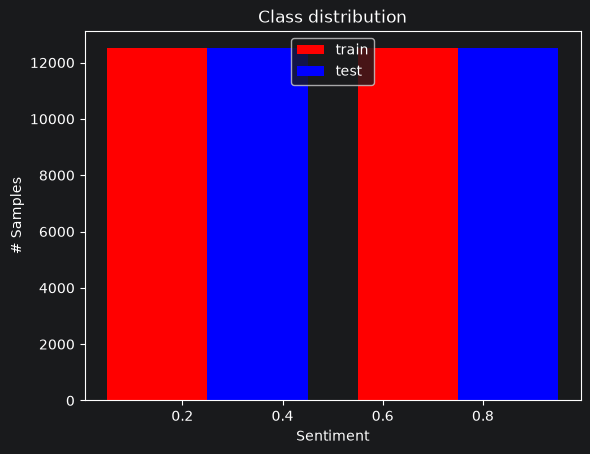

In [13]:
plt.hist([train_labels,test_labels], bins=2, label=['train','test'],
         color=["red", "blue"], align="mid")
plt.legend(loc='upper center')
plt.title('Class distribution')
plt.xlabel('Sentiment')
plt.ylabel('# Samples')
plt.show()

Then we visualize sentiment scores.


In [14]:
train_scores = df[df.split == 'train'].score.values
test_scores = df[df.split == 'test'].score.values

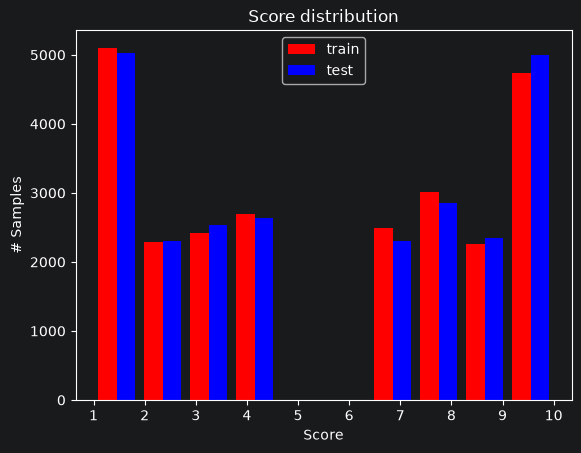

In [15]:
plt.xticks(range(1,11))
plt.hist([train_scores,test_scores], bins=10, label=['train','test'], color=["red", "blue"], align="mid")
plt.legend(loc='upper center')
plt.title('Score distribution')
plt.xlabel('Score')
plt.ylabel('# Samples')

plt.show()

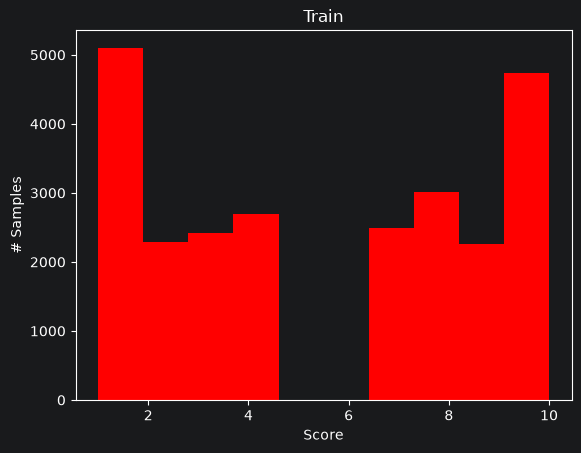

In [16]:
plot1 = plt.figure(1)
plt.hist(train_scores, 10, color="red")
plt.xlabel('Score')
plt.ylabel('# Samples')
plt.title("Train")
plt.show()

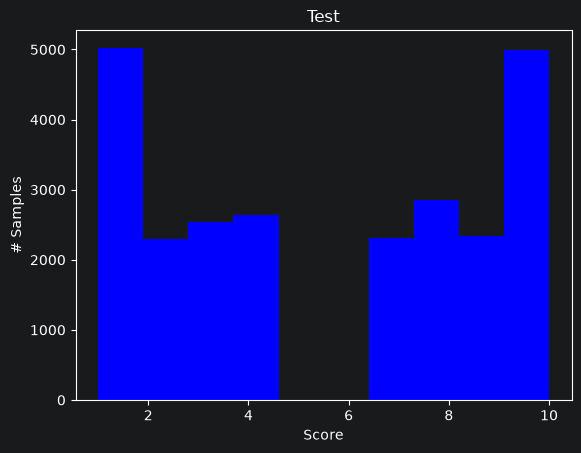

In [17]:
plot2 = plt.figure(2)
plt.hist(test_scores, 10, color="blue")
plt.xlabel('Score')
plt.ylabel('# Samples')
plt.title("Test")
plt.show()

Last, we check text length distribution.

In [18]:
# preliminaries
import nltk
from nltk.tokenize import word_tokenize

# necessary for being able to tokenize
nltk.download('punkt_tab')
nltk.download('punkt')

[nltk_data] Downloading package punkt_tab to /Users/paolo/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to /Users/paolo/nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [19]:
train_texts = df[df.split == 'train'].text.values
test_texts = df[df.split == 'test'].text.values

# this may take about a minute on standard hardware:
train_lengths = [len(word_tokenize(text)) for text in tqdm(train_texts)]
test_lengths = [len(word_tokenize(text)) for text in tqdm(test_texts)]

100%|██████████| 25000/25000 [00:10<00:00, 2276.34it/s]


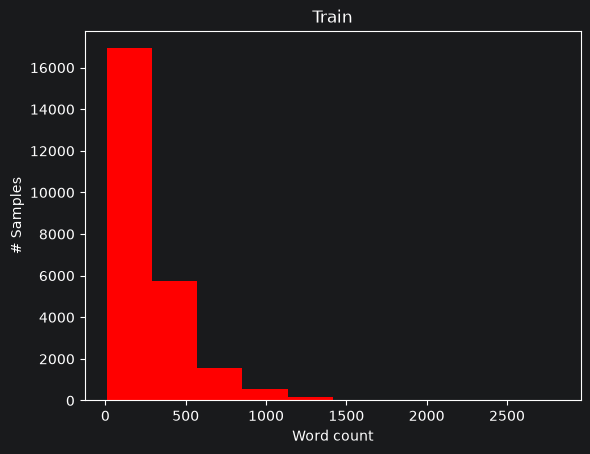

In [20]:
plot1 = plt.figure(1)
plt.hist(train_lengths, color="red")
plt.xlabel('Word count')
plt.ylabel('# Samples')
plt.title("Train")
plt.show()

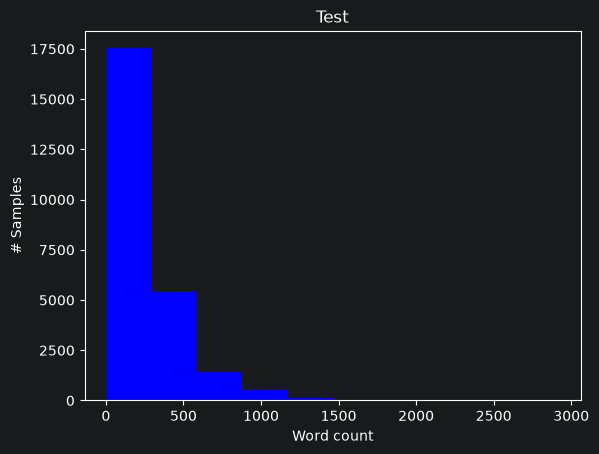

In [21]:
plot2 = plt.figure(2)
plt.hist(test_lengths, 10, color="blue")
plt.xlabel('Word count')
plt.ylabel('# Samples')
plt.title("Test")
plt.show()